# 🌧️ Weather-Based Rainfall Prediction for Pakistan

**Task:** binary classification — *will it rain tomorrow (≥ 1 mm) in a given city?*
**User:** farmers in Pakistan's main farming regions, deciding whether to irrigate, spray pesticide or dry a harvest tomorrow. Irrigating before rain wastes water, spraying before rain washes the pesticide off.

**Why these 4 cities:** each represents a different farming system and rain pattern.

| City | Farming region it represents | Why rain tomorrow matters |
|---|---|---|
| Lahore | Punjab irrigated plains | irrigation and spraying decisions; monsoon rice and cotton |
| Karachi | Lower Sindh coast | coastal vegetable farming; monsoon rain |
| Islamabad | Pothohar plateau (barani, rain-fed) | wheat and other crops depend almost entirely on rain |
| Quetta | Balochistan valleys | apple and grape orchards depend on winter rain |

**Success metric:** F1-score of the "rain" class on the held-out test set (supported by ROC-AUC and PR-AUC),
because rain days are the minority class and plain accuracy would be misleading.

| Step | Section |
|---|---|
| Data | 1 |
| 1. EDA (≥ 5 plots) | 2 |
| 3. Time-ordered train / validation / test split | 3 |
| 2. Pre-processing inside a scikit-learn `Pipeline` | 4 |
| 4. Baselines + 4 algorithms | 5 |
| 5. Tuning with 5-fold (time-series) cross-validation | 5 |
| 6. Evaluation, over/under-fitting, test set used once, error analysis | 6–8 |
| 7. Saving with `joblib` | 9 |

> Run `python src/download_data.py` once before this notebook.

In [1]:
# imports, settings and file paths
import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))
os.environ["PYTHONPATH"] = str(SRC) + os.pathsep + os.environ.get("PYTHONPATH", "")

import rainfall_features as rf
from rainfall_features import CATEGORICAL, INPUT_COLUMNS, TARGET, build_pipeline

DATA = ROOT / "data" / "weather_pakistan.csv"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
QUICK_TEST = os.environ.get("QUICK_TEST") == "1"
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
RAIN_C, DRY_C = "#2563eb", "#f59e0b"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5


## 1. Data
Two public sources, merged per city and date by `src/download_data.py`:
1. **Open-Meteo Historical Weather API** (ERA5 reanalysis) — CC BY 4.0
2. **NASA POWER Daily API** (MERRA-2 / CERES) — free, acknowledgement requested

4 cities (Karachi, Lahore, Islamabad, Quetta) × 2020–2024 daily records (most recent 5 years of the 2010–2024 download, ≈ 7,300 rows). Provenance (source, method, licence, download date) is in `data/dataset_info.json`.

In [2]:
# load the 16-feature dataset and the full 40-feature dataset
df = pd.read_csv(DATA, parse_dates=["date"])
full = pd.read_csv(ROOT / "data" / "weather_pakistan_all_features.csv", parse_dates=["date"])
TRAIN_END = "2022-12-31"
info = json.loads((ROOT / "data" / "dataset_info.json").read_text())

print(f"Rows: {len(df):,} | input features: {len(INPUT_COLUMNS)} | cities: {df['city'].nunique()}")
print(f"Period: {df['date'].min().date()} → {df['date'].max().date()} | downloaded: {info['downloaded_on_utc']} UTC")
assert len(df) >= 5000 and len(INPUT_COLUMNS) >= 15, "Guideline: >= 5,000 rows and >= 15 features"
for s in info["sources"]:
    print(f"• {s['name']}\n    licence: {s['licence']}")
df.head()

Rows: 7,304 | input features: 16 | cities: 4
Period: 2020-01-01 → 2024-12-30 | downloaded: 2026-11-20 19:45 UTC
• Open-Meteo Historical Weather API (ERA5 / ERA5-Land reanalysis)
    licence: CC BY 4.0 (https://open-meteo.com/en/licence)
• NASA POWER Daily Point API (MERRA-2 / CERES)
    licence: No restrictions on use; acknowledgement requested (https://power.larc.nasa.gov/docs/referencing/)


,date,city,month,nasa_cloud_amt,nasa_prectotcorr,pressure_change_24h,precip_3d_sum,nasa_qv2m,cloud_cover_mean,pressure_msl_mean,nasa_ps,precipitation_sum,nasa_rh2m,wind_speed_10m_max,wind_direction_10m_dominant,temperature_2m_max,precip_7d_sum,rain_tomorrow
0,2020-01-01,Islamabad,1,97.68,0.00,1.458333,0.0,3.70,96.291667,1022.504167,95.83,0.0,52.16,11.1,2,15.2,0.0,0
1,2020-01-01,Karachi,1,71.84,0.00,0.929167,0.0,4.62,68.833333,1018.195833,101.26,0.0,45.36,31.6,56,20.3,0.0,0
2,2020-01-01,Lahore,1,97.02,0.00,1.412500,0.0,3.94,92.125000,1022.729167,99.75,0.0,57.69,10.1,44,13.5,0.0,0
3,2020-01-01,Quetta,1,34.66,0.00,0.612500,0.0,2.98,27.375000,1018.912500,82.07,0.0,58.12,17.4,161,9.4,0.0,1
4,2020-01-02,Islamabad,1,93.08,0.01,0.783333,0.0,4.17,99.000000,1023.287500,95.90,0.0,51.80,11.6,308,15.0,0.0,1


In [3]:
# summary statistics of every feature
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,7304,2022-07-01 12:00:00,2020-01-01 00:00:00,2021-04-01 00:00:00,2022-07-01 12:00:00,2023-10-01 00:00:00,2024-12-30 00:00:00,NaN
month,7304.0,6.518072,1.0,4.0,7.0,10.0,12.0,3.448008
nasa_cloud_amt,7304.0,34.659666,0.05,7.45,25.265,58.56,99.98,30.26578
nasa_prectotcorr,7304.0,2.810137,0.0,0.0,0.0,0.56,466.31,14.76873
pressure_change_24h,7304.0,0.00029,-8.845833,-1.091667,-0.029167,1.075,9.7875,1.726291
precip_3d_sum,7304.0,4.566662,0.0,0.0,0.0,2.5,227.5,12.318204
nasa_qv2m,7304.0,10.548554,0.76,5.3275,8.9,16.26,24.14,6.171651
cloud_cover_mean,7304.0,28.098896,0.0,1.75,17.458333,47.083333,100.0,29.558926
pressure_msl_mean,7304.0,1009.89563,991.895833,1003.905208,1010.204167,1016.004167,1029.520833,7.279974
nasa_ps,7304.0,93.816859,80.93,90.52,96.345,99.36,101.52,7.176528


### 1.1 Feature selection (40 → 16), using the training years only
`download_data.py` collects **40** features (`data/weather_pakistan_all_features.csv`). To keep the 2023 validation
and 2024 test years completely unseen, the selection uses **only 2020–2022**:
1. **Importance:** a Random Forest is fitted on 2020–2021 and scored on 2022 with permutation importance (how much
   PR-AUC drops when a feature is shuffled), averaged over 3 random seeds.
2. **Redundancy:** walking down the ranking, a feature is skipped if it has |r| ≥ 0.9 with a feature already chosen
   (correlations from 2020–2022 only), e.g. `rain_sum` = `precipitation_sum`, `nasa_t2mdew` ≈ `nasa_qv2m`.
3. **Stop** when the importance is no longer positive. Features after that point add nothing on unseen data.
4. `city` and `month` are always kept, because rain seasons differ by city (monsoon vs winter rain).

The result (15 numeric + city = **16 features**) is fixed in `SELECTED_NUMERIC` in `src/rainfall_features.py`; the
cell below recomputes it and checks that it matches.

Selected (training years only): ['city', 'month', 'nasa_cloud_amt', 'nasa_prectotcorr', 'pressure_change_24h', 'precip_3d_sum', 'nasa_qv2m', 'cloud_cover_mean', 'pressure_msl_mean', 'nasa_ps', 'precipitation_sum', 'nasa_rh2m', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'temperature_2m_max', 'precip_7d_sum']
16 features from 40 collected

skip nasa_t2mdew                  |r| >= 0.9 with nasa_qv2m
skip pressure_msl_min             |r| >= 0.9 with pressure_msl_mean


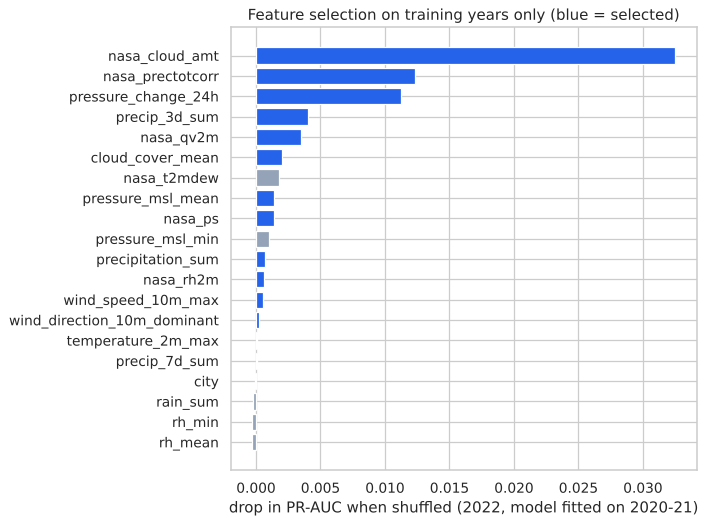

In [4]:
# feature selection 40 -> 16 using only the training years
from sklearn.compose import ColumnTransformer as _CT
from sklearn.impute import SimpleImputer as _SI
from sklearn.pipeline import Pipeline as _P
from sklearn.preprocessing import OneHotEncoder as _OHE

sel_train = full[full["date"] <= TRAIN_END]
fit_part = sel_train[sel_train["date"] <= "2021-12-31"]
score_part = sel_train[sel_train["date"] >= "2022-01-01"]
all_num = list(rf.ALL_NUMERIC)

def perm_importance(seed):
    m = _P([("prep", _CT([("num", _SI(strategy="median"), all_num),
                          ("city", _OHE(handle_unknown="ignore"), ["city"])])),
            ("rf", RandomForestClassifier(300, min_samples_leaf=10, class_weight="balanced_subsample",
                                          random_state=seed, n_jobs=-1))])
    m.fit(fit_part[["city"] + all_num], fit_part[TARGET])
    r = permutation_importance(m, score_part[["city"] + all_num], score_part[TARGET],
                               scoring="average_precision", n_repeats=10, random_state=seed, n_jobs=-1)
    return pd.Series(r.importances_mean, index=["city"] + all_num)

sel_imp = sum(perm_importance(s) for s in (1, 2, 3)) / 3
sel_corr = sel_train[all_num].corr().abs()
chosen, log = ["month"], []
for f in sel_imp.drop(["city", "month", "day_of_year"]).sort_values(ascending=False).index:
    if sel_imp[f] <= 0:
        break
    clash = [g for g in chosen if sel_corr.loc[f, g] >= 0.9]
    if clash:
        log.append(f"skip {f:28s} |r| >= 0.9 with {clash[0]}")
        continue
    chosen.append(f)

print("Selected (training years only):", ["city"] + chosen)
print(f"{len(chosen) + 1} features from {len(all_num) + 1} collected\n")
print("\n".join(log))
assert sorted(chosen) == sorted(rf.SELECTED_NUMERIC), "selection differs from SELECTED_NUMERIC"

top = sel_imp.sort_values(ascending=False).head(20)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=[RAIN_C if f in chosen or f == "city" else "#94a3b8" for f in top.index])
plt.xlabel("drop in PR-AUC when shuffled (2022, model fitted on 2020-21)")
plt.title("Feature selection on training years only (blue = selected)")
savefig("00_feature_selection")

## 2. Exploratory Data Analysis
### 2.1 Class balance (Plot 1)

Rain rate: 16.7% → imbalanced; accuracy alone is misleading, use F1 / PR-AUC.


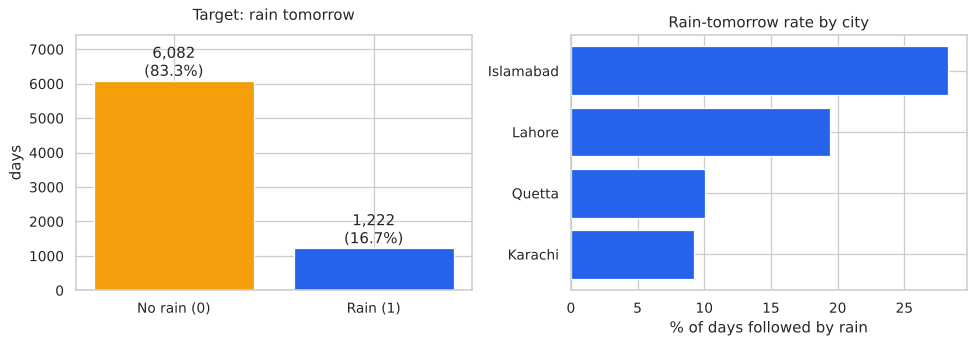

In [5]:
# plot 1: class balance (rain vs no rain)
counts = df[TARGET].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["No rain (0)", "Rain (1)"], counts.values, color=[DRY_C, RAIN_C])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Target: rain tomorrow", pad=12)
axes[0].set_ylim(0, counts.max() * 1.22)
axes[0].set_ylabel("days")
city_rate = df.groupby("city")[TARGET].mean().sort_values()
axes[1].barh(city_rate.index, city_rate.values * 100, color=RAIN_C)
axes[1].set_xlabel("% of days followed by rain")
axes[1].set_title("Rain-tomorrow rate by city")
savefig("01_class_balance")
print(f"Rain rate: {df[TARGET].mean():.1%} → imbalanced; accuracy alone is misleading, use F1 / PR-AUC.")

### 2.2 Missing values (Plot 2)
Checked at three levels:
1. **Raw API data:** NASA POWER marks missing values with `-999` and Open-Meteo with `null`; both become `NaN` when
   loading. `download_data.py` counts them for the study period and stores the count in `dataset_info.json`.
2. **Final dataset:** % missing in each of the 17 features (left).
3. **Missing days:** every city must have one row per day (right). A missing day would silently break the
   look-back features such as `precip_7d_sum`.

The look-back features of 1 January 2020 are complete because the raw download starts in 2010, so the previous
days exist. The pipeline still contains a median `SimpleImputer`, because the live app can receive incomplete data.

Missing cells in final dataset: 0 of 116,864
Raw API missing values (NASA -999 / Open-Meteo null) in the study period: 0
City-years with missing days: 0
Pipeline keeps SimpleImputer(median) for robustness - live app inputs can be incomplete.


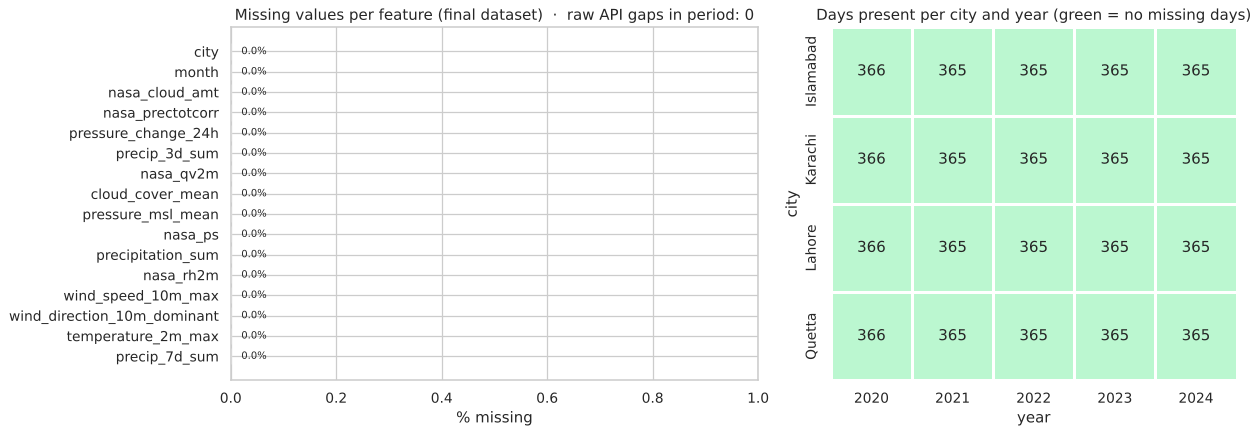

In [6]:
# plot 2: missing values per feature and per city-year
raw_missing = info.get("raw_missing_values_in_period", {}).get("total", "n/a")
miss = df[INPUT_COLUMNS].isna().mean() * 100
days = df.groupby(["city", df["date"].dt.year]).size().unstack()
expected = pd.Series({y: (366 if y % 4 == 0 else 365) for y in days.columns})
expected.iloc[-1] -= 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].barh(miss.index[::-1], miss.values[::-1], color=RAIN_C)
for y, v in enumerate(miss.values[::-1]):
    axes[0].text(max(v, 0) + 0.02, y, f"{v:.1f}%", va="center", fontsize=8)
axes[0].set_xlim(0, max(1.0, miss.max() * 1.2))
axes[0].set_xlabel("% missing")
axes[0].set_title(f"Missing values per feature (final dataset)  ·  raw API gaps in period: {raw_missing}")
complete = days.eq(expected, axis=1)
sns.heatmap(complete.astype(int), annot=days, fmt="d", cmap=["#fca5a5", "#bbf7d0"], vmin=0, vmax=1,
            cbar=False, linewidths=2, linecolor="white", ax=axes[1])
axes[1].set_title("Days present per city and year (green = no missing days)")
axes[1].set_xlabel("year")
savefig("02_missing_values")

print(f"Missing cells in final dataset: {int(df[INPUT_COLUMNS].isna().sum().sum())} of {df[INPUT_COLUMNS].size:,}")
print(f"Raw API missing values (NASA -999 / Open-Meteo null) in the study period: {raw_missing}")
gaps = (days.sub(expected, axis=1) != 0).sum().sum()
print(f"City-years with missing days: {gaps}")
print("Pipeline keeps SimpleImputer(median) for robustness - live app inputs can be incomplete.")

### 2.3 Feature distributions (Plot 3)

Skewness (|skew| > 1 = strongly skewed):
precipitation_sum     9.61
precip_3d_sum         6.06
precip_7d_sum         4.11
wind_speed_10m_max    0.98
cloud_cover_mean      0.92
nasa_qv2m             0.48
pressure_msl_mean    -0.11
nasa_rh2m            -0.34
temperature_2m_max   -0.64


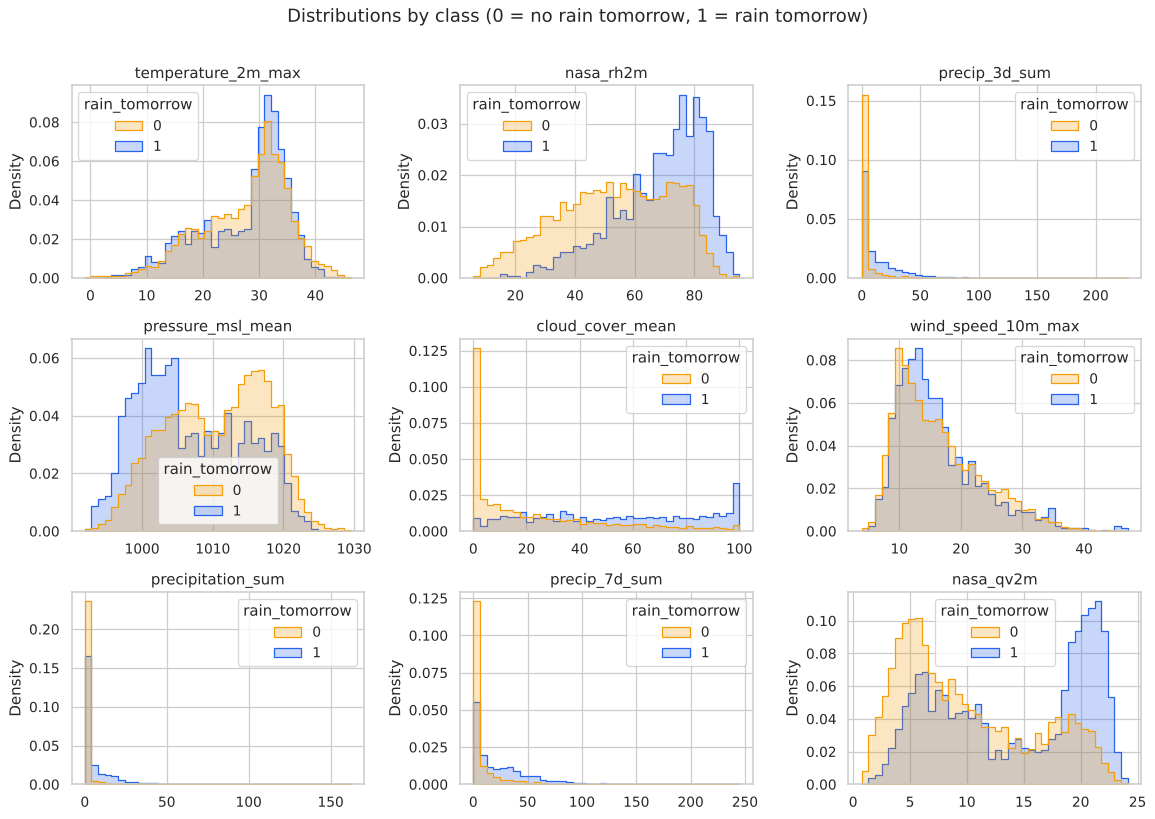

In [7]:
# plot 3: distributions of key features
key = ["temperature_2m_max", "nasa_rh2m", "precip_3d_sum", "pressure_msl_mean", "cloud_cover_mean",
       "wind_speed_10m_max", "precipitation_sum", "precip_7d_sum", "nasa_qv2m"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), key):
    sns.histplot(data=df, x=col, hue=TARGET, bins=40, stat="density", common_norm=False,
                 palette={0: DRY_C, 1: RAIN_C}, element="step", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distributions by class (0 = no rain tomorrow, 1 = rain tomorrow)", y=1.01)
savefig("03_distributions")
print("Skewness (|skew| > 1 = strongly skewed):")
print(df[key].skew().round(2).sort_values(ascending=False).to_string())

### 2.4 Outliers (Plot 4)
Outliers are counted with the 1.5×IQR rule. **Note for rainfall:** most days are completely dry, so the IQR of
`precipitation_sum`, `nasa_prectotcorr` and `precip_7d_sum` is (almost) zero and the IQR rule flags **every** rain
day as an "outlier". These are real weather events, not errors. So we do **not** delete rows. Instead the pipeline
**clips** every numeric feature to its training 1st–99th percentile (winsorising), which limits extreme storms
without removing information.

% of rows flagged as outliers (top 10):
precipitation_sum      20.33
nasa_prectotcorr       19.47
precip_3d_sum          17.00
precip_7d_sum          14.10
pressure_change_24h     1.70
wind_speed_10m_max      1.51
temperature_2m_max      0.73
cloud_cover_mean        0.00
nasa_cloud_amt          0.00
nasa_qv2m               0.00

Days with exactly 0 mm rain: 70.6% -> rainfall IQR = 0.20 mm, so any rain day counts as an IQR 'outlier' (real events, kept and clipped, not deleted).


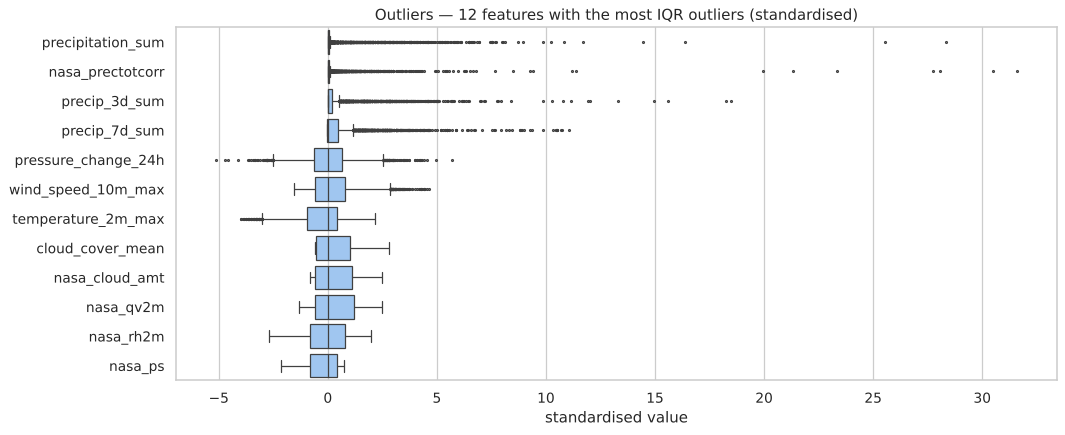

In [8]:
# plot 4: outliers with the IQR rule
num = df[rf.RAW_NUMERIC].drop(columns=["month"])
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
outlier_pct = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean().sort_values(ascending=False) * 100
show = outlier_pct.head(12).index
z = (num[show] - num[show].median()) / num[show].std()
plt.figure(figsize=(12, 5))
sns.boxplot(data=z, orient="h", color="#93c5fd", fliersize=1.5)
plt.xlabel("standardised value")
plt.title("Outliers — 12 features with the most IQR outliers (standardised)")
savefig("04_outliers_boxplot")
print("% of rows flagged as outliers (top 10):")
print(outlier_pct.head(10).round(2).to_string())
dry = (df["precipitation_sum"] == 0).mean()
print(f"\nDays with exactly 0 mm rain: {dry:.1%} -> rainfall IQR = {iqr['precipitation_sum']:.2f} mm, "
      "so any rain day counts as an IQR 'outlier' (real events, kept and clipped, not deleted).")

### 2.5 Correlations (Plot 5)
Computed on the **training years (2020–2022) only**, because they were used for feature selection.

Strongest correlations with rain_tomorrow:
nasa_cloud_amt                 0.470
cloud_cover_mean               0.424
precipitation_sum              0.340
precip_7d_sum                  0.339
precip_3d_sum                  0.325
nasa_rh2m                      0.298
nasa_qv2m                      0.267
wind_direction_10m_dominant   -0.219
pressure_msl_mean             -0.176
nasa_prectotcorr               0.169

Most redundant feature pairs (|r| highest) — handled by regularisation / tree models:
pressure_msl_mean  temperature_2m_max   -0.827
nasa_cloud_amt     cloud_cover_mean      0.793
precip_3d_sum      precip_7d_sum         0.755
nasa_qv2m          pressure_msl_mean    -0.706
precip_3d_sum      precipitation_sum     0.686
nasa_qv2m          nasa_rh2m             0.685
                   temperature_2m_max    0.573
precipitation_sum  precip_7d_sum         0.500


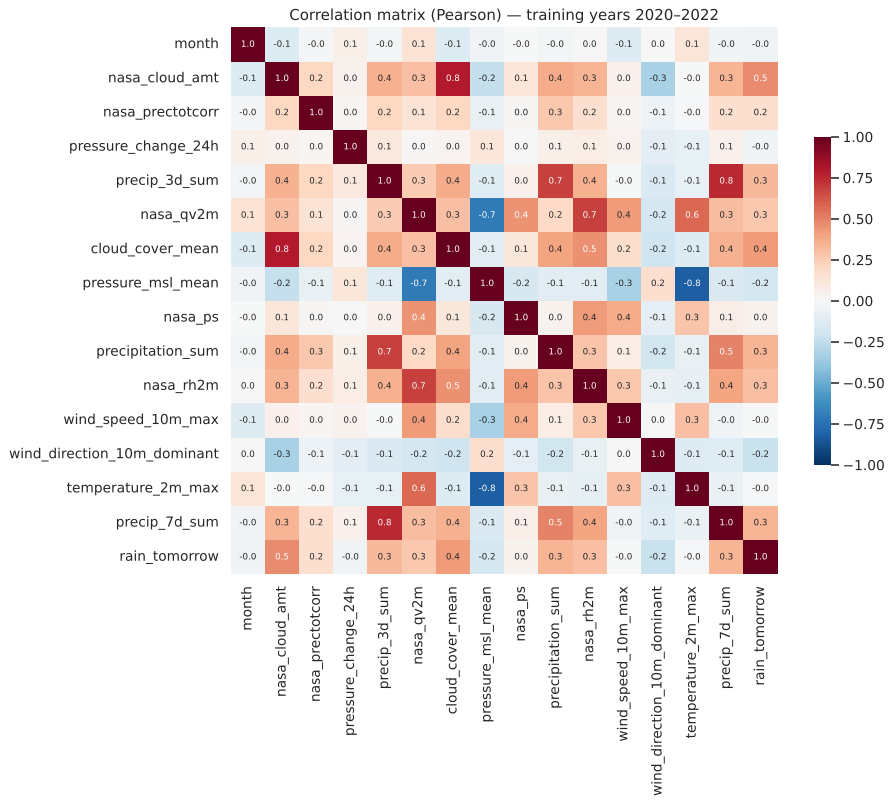

In [9]:
# plot 5: correlation heatmap (training years only)
corr_cols = rf.RAW_NUMERIC + [TARGET]
corr = df[df["date"] <= TRAIN_END][corr_cols].corr(numeric_only=True)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.6}, xticklabels=True, yticklabels=True)
plt.title("Correlation matrix (Pearson) — training years 2020–2022")
savefig("05_correlation_heatmap")
tc = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Strongest correlations with rain_tomorrow:")
print(tc.head(10).round(3).to_string())
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False))
print("\nMost redundant feature pairs (|r| highest) — handled by regularisation / tree models:")
print(pairs.head(8).round(3).to_string())

### 2.6 Seasonality (Plot 6)

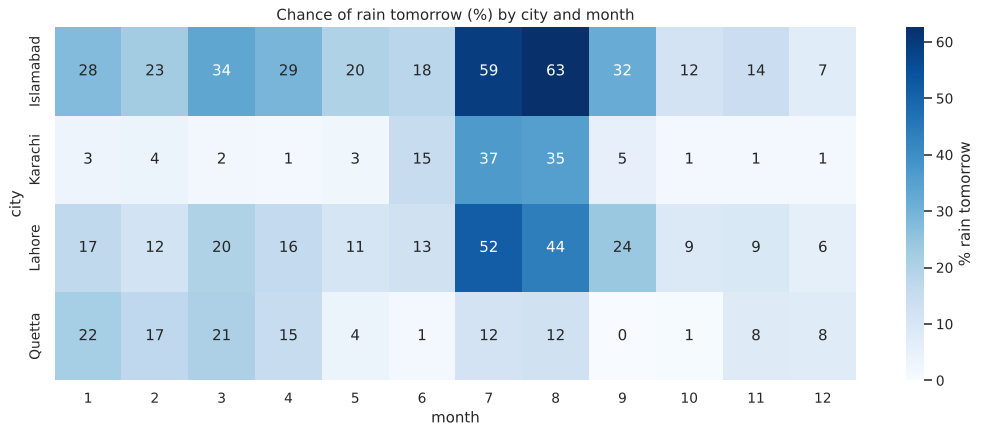

In [10]:
# plot 6: chance of rain by city and month
season = df.pivot_table(index="city", columns=df["date"].dt.month, values=TARGET, aggfunc="mean") * 100
plt.figure(figsize=(12, 5))
sns.heatmap(season, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% rain tomorrow"})
plt.xlabel("month")
plt.title("Chance of rain tomorrow (%) by city and month")
savefig("06_seasonality_city_month")

### 2.7 Key predictors vs. target (Plot 7)

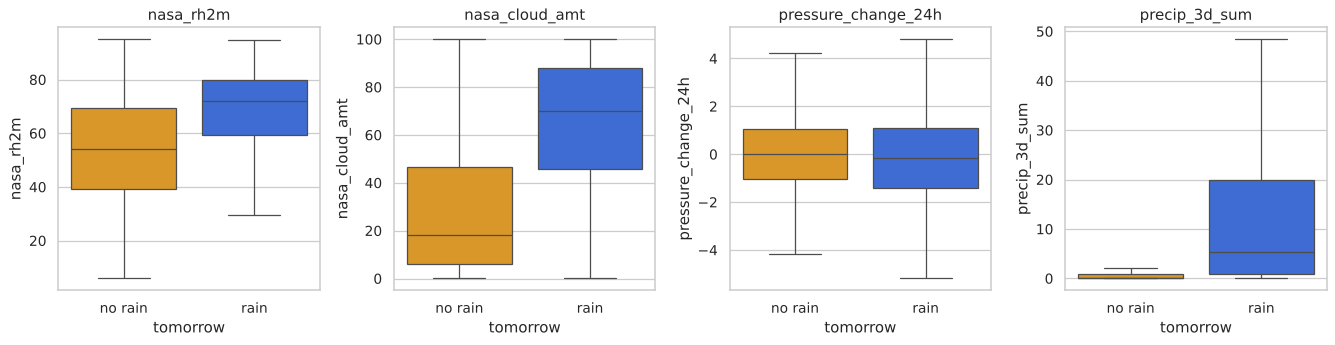

In [11]:
# plot 7: key predictors for rain vs no-rain days
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["nasa_rh2m", "nasa_cloud_amt", "pressure_change_24h", "precip_3d_sum"]):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette={0: DRY_C, 1: RAIN_C},
                legend=False, showfliers=False, ax=ax)
    ax.set_xticks([0, 1], ["no rain", "rain"])
    ax.set_xlabel("tomorrow")
    ax.set_title(col)
savefig("07_predictors_vs_target")

**EDA observations**
- **Class balance:** only **16.7%** of days are followed by rain (1,222 of 7,304), so the data is imbalanced. A model
  that always says "no rain" would already be 83% accurate, which is why we use F1, recall and PR-AUC instead of accuracy.
- **Cities:** Islamabad is the wettest (rain follows **28%** of days), then Lahore (19%), Quetta (10%) and Karachi (9%).
- **Seasonality:** the monsoon dominates. In July–August rain follows **59–63%** of days in Islamabad and 44–52% in
  Lahore, while October–December is almost dry everywhere. Quetta is different: its rain comes in **winter
  (January–March, 17–22%)** from western disturbances, and it is almost dry in the monsoon. That is why `month`
  and `city` are model inputs.
- **Strongest predictors:** before a rain day, the median cloud cover is **55% vs 12%** (NASA cloud amount 70% vs 18%),
  NASA humidity **72% vs 54%**, specific humidity 15.3 vs 8.2 g/kg, and the previous 7 days had **15.2 mm vs 0.3 mm**
  of rain. NASA cloud amount has the highest correlation with the target (r = 0.47 in the training years).
- **Distributions and outliers:** rainfall is extremely right-skewed (skew 9.6; 70.6% of days have exactly 0 mm), so
  extreme rain days look like IQR outliers but are real. We clip them to the 1st–99th percentile rather than
  delete them, and standardise all features because their scales differ (hPa vs mm vs %).
- **Redundancy:** after feature selection, no pair has |r| ≥ 0.9. The strongest remaining pairs are pressure vs max
  temperature (r = −0.83) and the two cloud measures (r = 0.79), which come from different sources and are both kept.
- **Missing values:** none in the final data and no missing days, because the raw APIs had no gaps for these cities
  and years.

## 3. Time-ordered split (no shuffling)
Weather is a time series: a random split would let the model "see the future" (days right after test days).
We split **by date**: train 2020–2022 (≈60%), validation 2023 (≈20%), test 2024 (≈20%).
The test set is touched **once**, at the very end.

In [12]:
# time-ordered split: train 2020-22, validation 2023, test 2024
df = df.sort_values(["date", "city"]).reset_index(drop=True)
train = df[df["date"] <= "2022-12-31"]
val = df[(df["date"] >= "2023-01-01") & (df["date"] <= "2023-12-31")]
test = df[df["date"] >= "2024-01-01"]

X_train, y_train = train[INPUT_COLUMNS], train[TARGET]
X_val, y_val = val[INPUT_COLUMNS], val[TARGET]
X_test, y_test = test[INPUT_COLUMNS], test[TARGET]

split = pd.DataFrame({
    "period": [f"{s['date'].min().date()} → {s['date'].max().date()}" for s in (train, val, test)],
    "rows": [len(train), len(val), len(test)],
    "share": [f"{len(s) / len(df):.1%}" for s in (train, val, test)],
    "rain rate": [f"{s[TARGET].mean():.1%}" for s in (train, val, test)],
}, index=["train", "validation", "test"])
split

,period,rows,share,rain rate
train,2020-01-01 → 2022-12-31,4384,60.0%,16.1%
validation,2023-01-01 → 2023-12-31,1460,20.0%,18.5%
test,2024-01-01 → 2024-12-30,1460,20.0%,16.8%


## 4. Pre-processing pipeline (fitted on training data only)
```
WeatherFeatureEngineer  → temp_range, dewpoint_depression, month/day-of-year sin-cos, is_monsoon, rained_today
ColumnTransformer
  numeric:     QuantileClipper(1%–99%) → SimpleImputer(median) → StandardScaler
  categorical: SimpleImputer(most_frequent) → OneHotEncoder(handle_unknown="ignore")   [city]
Classifier
```
Because everything is inside one `Pipeline`, `fit()` only ever learns percentiles, medians, means/stds and categories
from the rows it is trained on — inside cross-validation that means only the training fold. **No data leakage.**
Look-back features (yesterday's rain, 7-day totals, 24 h pressure change) were built in `download_data.py` from
*past* days only, and the target is *tomorrow's* rain, so no input contains future information.

In [13]:
# the preprocessing pipeline (fitted on training data only)
build_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{featur

## 5. Baselines, models and tuning
**Baselines** (any useful model must beat these):
- `DummyClassifier(stratified)` — random guessing at the class frequency
- **Persistence** — "it will rain tomorrow if it rained today" (a classic weather baseline)

**Models from the course:** Logistic Regression, K-Nearest Neighbours, Random Forest, Support Vector Machine
(`SVC`, RBF kernel). KNN, SVM and Logistic Regression depend on distances or weights, so they rely on the
`StandardScaler` inside the pipeline; Random Forest does not need scaling but gets the same pipeline.

**Tuning:** `RandomizedSearchCV` with **5-fold time-series cross-validation** on the training years: each fold
trains on earlier dates and validates on the following block of dates (`TimeSeriesSplit` over unique dates, so
one day's 4 cities never straddle a fold boundary). Models are ranked by **average precision (PR-AUC)**, which
is threshold-independent and suited to an imbalanced target; the decision threshold is tuned afterwards.

In [14]:
# 5 forward-chaining time-series folds for cross-validation
def date_folds(dates: pd.Series, n_splits: int = 5):
    """5 forward-chaining folds over unique dates -> positional indices."""
    uniq = np.sort(dates.unique())
    folds = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits).split(uniq):
        folds.append((np.flatnonzero(dates.isin(uniq[tr]).to_numpy()),
                      np.flatnonzero(dates.isin(uniq[va]).to_numpy())))
    return folds

cv_folds = date_folds(train["date"], n_splits=5)
for i, (a, b) in enumerate(cv_folds, 1):
    print(f"fold {i}: train {train['date'].iloc[a].min().date()}–{train['date'].iloc[a].max().date()} "
          f"| validate {train['date'].iloc[b].min().date()}–{train['date'].iloc[b].max().date()}")

fold 1: train 2020-01-01–2020-07-04 | validate 2020-07-05–2021-01-02
fold 2: train 2020-01-01–2021-01-02 | validate 2021-01-03–2021-07-03
fold 3: train 2020-01-01–2021-07-03 | validate 2021-07-04–2022-01-01
fold 4: train 2020-01-01–2022-01-01 | validate 2022-01-02–2022-07-02
fold 5: train 2020-01-01–2022-07-02 | validate 2022-07-03–2022-12-31


In [15]:
# helper to compute all metrics
def scores(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {
        "F1": f1_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }

results, probas_val = {}, {}

dummy = build_pipeline(DummyClassifier(strategy="stratified", random_state=SEED)).fit(X_train, y_train)
probas_val["Baseline: Dummy (stratified)"] = dummy.predict_proba(X_val)[:, 1]
results["Baseline: Dummy (stratified)"] = scores(y_val, probas_val["Baseline: Dummy (stratified)"])

persist_val = (X_val["precipitation_sum"] >= rf.RAIN_THRESHOLD_MM).astype(float).to_numpy()
probas_val["Baseline: Persistence"] = persist_val
results["Baseline: Persistence"] = scores(y_val, persist_val)
pd.DataFrame(results).T.round(3)

,F1,Precision,Recall,Accuracy,ROC-AUC,PR-AUC
Baseline: Dummy (stratified),0.143,0.149,0.137,0.696,0.480,0.180
Baseline: Persistence,0.533,0.533,0.533,0.827,0.714,0.371


In [16]:
# baselines + 4 models tuned with RandomizedSearchCV
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced"),
        {"model__C": loguniform(1e-3, 1e2)},
        12,
    ),
    "K-Nearest Neighbours": (
        KNeighborsClassifier(n_jobs=1),
        {"model__n_neighbors": randint(15, 120), "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
        6,
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
        {"model__n_estimators": [100, 200], "model__max_depth": [8, 12, 16],
         "model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.3]},
        6,
    ),
    "SVM (RBF kernel)": (
        SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED),
        {"model__C": loguniform(0.1, 100), "model__gamma": loguniform(1e-3, 1)},
        8,
    ),
}

searches, cv_rows = {}, []
for name, (model, grid, n_iter) in search_spaces.items():
    n_iter = 1 if QUICK_TEST else n_iter
    t0 = time.time()
    search = RandomizedSearchCV(
        build_pipeline(model), grid, n_iter=n_iter, cv=cv_folds,
        scoring={"ap": "average_precision", "roc_auc": "roc_auc", "f1": "f1"}, refit="ap",
        n_jobs=-1, random_state=SEED, return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    cvr = search.cv_results_
    cv_rows.append({
        "model": name,
        "CV PR-AUC": cvr["mean_test_ap"][i], "CV PR-AUC std": cvr["std_test_ap"][i],
        "train-fold PR-AUC": cvr["mean_train_ap"][i],
        "CV ROC-AUC": cvr["mean_test_roc_auc"][i], "CV F1": cvr["mean_test_f1"][i],
        "minutes": (time.time() - t0) / 60,
        "best params": {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                        for k, v in search.best_params_.items()},
    })
    print(f"✔ {name:22s} CV PR-AUC {cvr['mean_test_ap'][i]:.3f} ± {cvr['std_test_ap'][i]:.3f} "
          f"({(time.time() - t0) / 60:.1f} min)  {search.best_params_}")

cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(3)

✔ Logistic Regression    CV PR-AUC 0.583 ± 0.125 (0.0 min)  {'model__C': np.float64(0.006026889128682512)}
✔ K-Nearest Neighbours   CV PR-AUC 0.553 ± 0.101 (0.1 min)  {'model__n_neighbors': 29, 'model__p': 1, 'model__weights': 'distance'}
✔ Random Forest          CV PR-AUC 0.611 ± 0.081 (0.2 min)  {'model__n_estimators': 100, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 16}
✔ SVM (RBF kernel)       CV PR-AUC 0.571 ± 0.107 (0.5 min)  {'model__C': np.float64(0.3511356313970407), 'model__gamma': np.float64(0.003549878832196502)}


,CV PR-AUC,CV PR-AUC std,train-fold PR-AUC,CV ROC-AUC,CV F1,minutes,best params
model,,,,,,,
Logistic Regression,0.583,0.125,0.588,0.886,0.542,0.032,{'C': 0.006}
K-Nearest Neighbours,0.553,0.101,1.000,0.863,0.350,0.080,"{'n_neighbors': 29, 'p': 1, 'weights': 'distan..."
Random Forest,0.611,0.081,0.840,0.897,0.588,0.200,"{'n_estimators': 100, 'min_samples_leaf': 10, ..."
SVM (RBF kernel),0.571,0.107,0.590,0.885,0.541,0.462,"{'C': 0.3511, 'gamma': 0.0035}"


## 6. Model comparison on the validation set (2023)

In [17]:
# compare all models on the 2023 validation set
train_scores = {}
for name, search in searches.items():
    est = search.best_estimator_
    probas_val[name] = est.predict_proba(X_val)[:, 1]
    results[name] = scores(y_val, probas_val[name])
    train_scores[name] = scores(y_train, est.predict_proba(X_train)[:, 1])

comparison = pd.DataFrame(results).T
comparison["Train PR-AUC"] = pd.Series({k: v["PR-AUC"] for k, v in train_scores.items()})
comparison["Train−Val PR-AUC gap"] = comparison["Train PR-AUC"] - comparison["PR-AUC"]
comparison = comparison.sort_values("PR-AUC", ascending=False)
comparison.to_csv(MODELS / "model_comparison_validation.csv")
comparison.round(3)

,F1,Precision,Recall,Accuracy,ROC-AUC,PR-AUC,Train PR-AUC,Train−Val PR-AUC gap
Random Forest,0.590,0.509,0.700,0.820,0.886,0.625,0.848,0.223
SVM (RBF kernel),0.492,0.658,0.393,0.850,0.876,0.601,0.603,0.002
Logistic Regression,0.578,0.460,0.778,0.790,0.875,0.599,0.617,0.019
K-Nearest Neighbours,0.455,0.669,0.344,0.847,0.863,0.586,1.000,0.414
Baseline: Persistence,0.533,0.533,0.533,0.827,0.714,0.371,NaN,NaN
Baseline: Dummy (stratified),0.143,0.149,0.137,0.696,0.480,0.180,NaN,NaN


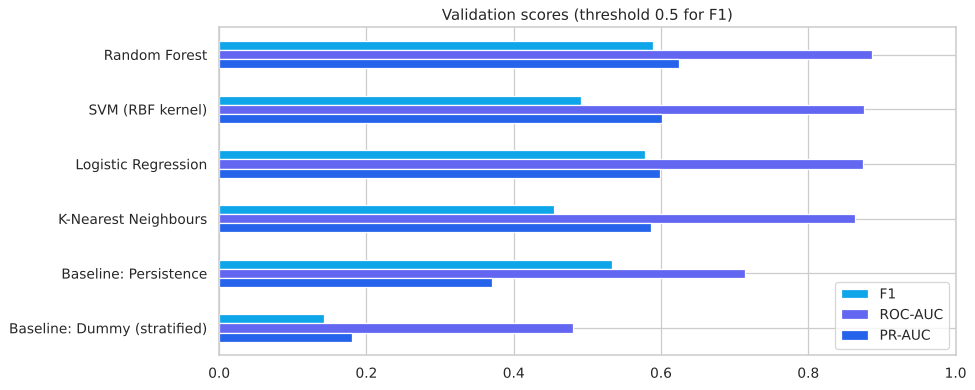

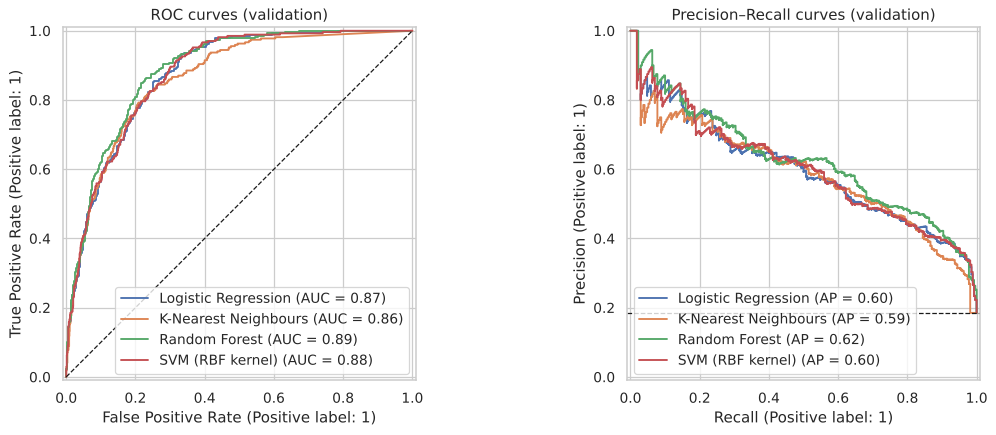

In [18]:
# plot: model comparison
fig, ax = plt.subplots(figsize=(11, 4.5))
comparison[["F1", "ROC-AUC", "PR-AUC"]].plot.barh(ax=ax, color=["#0ea5e9", "#6366f1", RAIN_C])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("Validation scores (threshold 0.5 for F1)")
ax.legend(loc="lower right")
savefig("08_model_comparison")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in searches:
    RocCurveDisplay.from_predictions(y_val, probas_val[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, probas_val[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].axhline(y_val.mean(), color="k", ls="--", lw=1, label="no-skill")
axes[0].set_title("ROC curves (validation)")
axes[1].set_title("Precision–Recall curves (validation)")
savefig("09_roc_pr_curves")

### Over-/under-fitting check
- A **large Train−Val gap** means over-fitting (memorising the training years).
- **Low train AND low validation** scores mean under-fitting (model too simple).
- The learning curve below trains the best model on growing slices of the training years and scores it on
  the validation year (2023).

Best model on validation PR-AUC: Random Forest
Final gap train−validation PR-AUC: 0.223


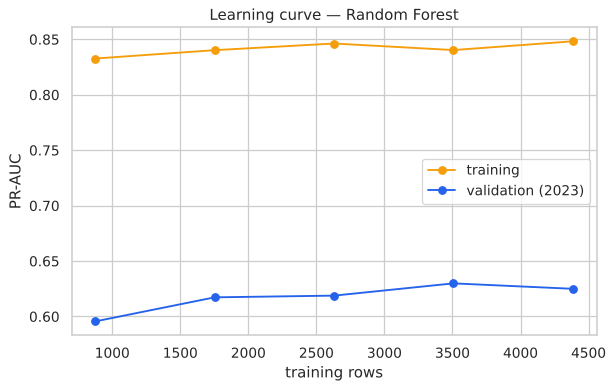

In [19]:
# over/under-fitting check with a learning curve
best_name = comparison.drop(index=[i for i in comparison.index if i.startswith("Baseline")])["PR-AUC"].idxmax()
best_search = searches[best_name]
print("Best model on validation PR-AUC:", best_name)

uniq_dates = np.sort(train["date"].unique())
sizes, tr_ap, va_ap = [0.2, 0.4, 0.6, 0.8, 1.0], [], []
for frac in sizes:
    cutoff = uniq_dates[int(frac * (len(uniq_dates) - 1))]
    part = train["date"] <= cutoff
    m = sklearn.base.clone(best_search.best_estimator_).fit(X_train[part], y_train[part])
    tr_ap.append(average_precision_score(y_train[part], m.predict_proba(X_train[part])[:, 1]))
    va_ap.append(average_precision_score(y_val, m.predict_proba(X_val)[:, 1]))

plt.figure(figsize=(7, 4.5))
n_rows = [int(f * len(train)) for f in sizes]
plt.plot(n_rows, tr_ap, "o-", label="training", color=DRY_C)
plt.plot(n_rows, va_ap, "o-", label="validation (2023)", color=RAIN_C)
plt.xlabel("training rows")
plt.ylabel("PR-AUC")
plt.title(f"Learning curve — {best_name}")
plt.legend()
savefig("10_learning_curve")
print(f"Final gap train−validation PR-AUC: {tr_ap[-1] - va_ap[-1]:.3f}")

### Threshold tuning (validation set only)
Classifiers output a probability; 0.5 is not automatically the best cut-off for an imbalanced problem.
We pick the threshold that maximises **F1 on validation** — the test set is still untouched.

Threshold 0.573: validation F1 0.613 (vs 0.590 at 0.5)


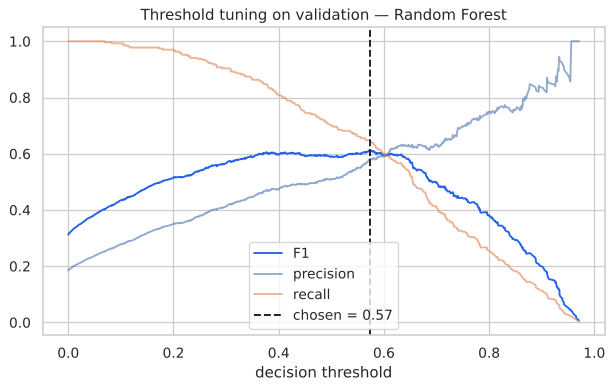

In [20]:
# choose the decision threshold on the validation set
prec, rec, thr = precision_recall_curve(y_val, probas_val[best_name])
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_i = int(np.nanargmax(f1s))
THRESHOLD = float(thr[best_i])

plt.figure(figsize=(7, 4.5))
plt.plot(thr, f1s, label="F1", color=RAIN_C)
plt.plot(thr, prec[:-1], label="precision", alpha=0.6)
plt.plot(thr, rec[:-1], label="recall", alpha=0.6)
plt.axvline(THRESHOLD, color="k", ls="--", label=f"chosen = {THRESHOLD:.2f}")
plt.xlabel("decision threshold")
plt.title(f"Threshold tuning on validation — {best_name}")
plt.legend()
savefig("11_threshold_tuning")
print(f"Threshold {THRESHOLD:.3f}: validation F1 {f1s[best_i]:.3f} (vs {results[best_name]['F1']:.3f} at 0.5)")

## 7. Final evaluation on the held-out test set (2024) — run once

In [21]:
# final evaluation on the 2024 test set (used once)
final_model = best_search.best_estimator_
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= THRESHOLD).astype(int)
test_metrics = scores(y_test, proba_test, THRESHOLD)
persist_test = (X_test["precipitation_sum"] >= rf.RAIN_THRESHOLD_MM).astype(float).to_numpy()
persist_metrics = scores(y_test, persist_test)

final_table = pd.DataFrame({f"{best_name} (thr {THRESHOLD:.2f})": test_metrics,
                            "Persistence baseline": persist_metrics}).T
final_table.to_csv(MODELS / "test_results.csv")
print(classification_report(y_test, pred_test, target_names=["no rain", "rain"], digits=3))
final_table.round(3)

              precision    recall  f1-score   support

     no rain      0.918     0.909     0.913      1214
        rain      0.571     0.602     0.586       246

    accuracy                          0.857      1460
   macro avg      0.745     0.755     0.750      1460
weighted avg      0.860     0.857     0.858      1460



,F1,Precision,Recall,Accuracy,ROC-AUC,PR-AUC
Random Forest (thr 0.57),0.586,0.571,0.602,0.857,0.879,0.636
Persistence baseline,0.528,0.528,0.528,0.841,0.716,0.359


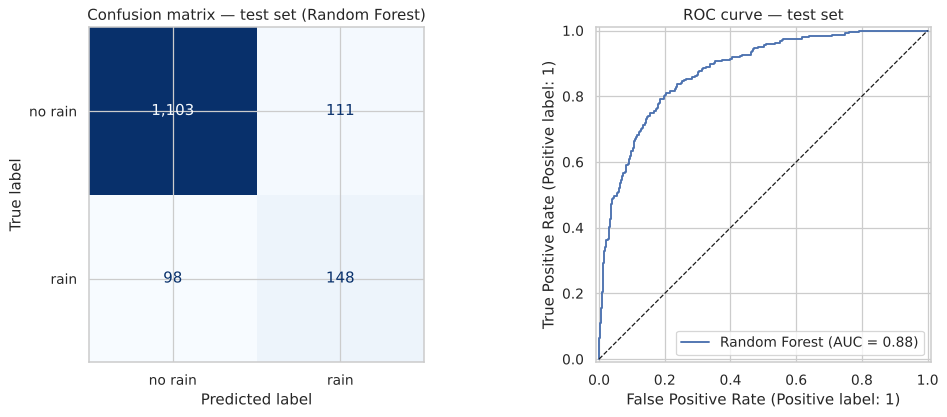

In [22]:
# plot: confusion matrix and ROC curve on the test set
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["no rain", "rain"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"Confusion matrix — test set ({best_name})")
RocCurveDisplay.from_predictions(y_test, proba_test, name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve — test set")
savefig("12_test_confusion_roc")

## 8. Error analysis

type
TN                  1103
TP                   148
FP (false alarm)     111
FN (missed rain)      98


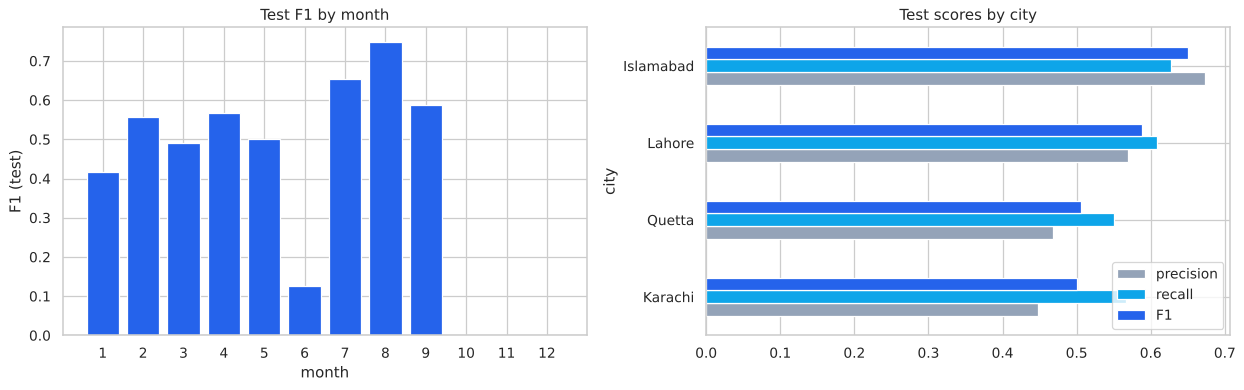

In [23]:
# error analysis by month and city
err = test[["date", "city", "precipitation_sum", TARGET]].copy()
err["proba"], err["pred"] = proba_test, pred_test
err["type"] = np.select(
    [(err.pred == 1) & (err[TARGET] == 1), (err.pred == 0) & (err[TARGET] == 0),
     (err.pred == 1) & (err[TARGET] == 0)],
    ["TP", "TN", "FP (false alarm)"], "FN (missed rain)")
by_month = err.groupby(err["date"].dt.month).apply(
    lambda g: pd.Series({"F1": f1_score(g[TARGET], g["pred"], zero_division=0),
                         "rain days": int(g[TARGET].sum())}), include_groups=False)
by_city = err.groupby("city").apply(
    lambda g: pd.Series({"F1": f1_score(g[TARGET], g["pred"], zero_division=0),
                         "recall": recall_score(g[TARGET], g["pred"], zero_division=0),
                         "precision": precision_score(g[TARGET], g["pred"], zero_division=0)}),
    include_groups=False).sort_values("F1")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(by_month.index, by_month["F1"], color=RAIN_C)
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("month")
axes[0].set_ylabel("F1 (test)")
axes[0].set_title("Test F1 by month")
by_city[["precision", "recall", "F1"]].plot.barh(ax=axes[1], color=["#94a3b8", "#0ea5e9", RAIN_C])
axes[1].set_title("Test scores by city")
savefig("13_error_analysis")
print(err["type"].value_counts().to_string())

**Error discussion**
- **Error types (2024 test set):** 148 rain days caught, **98 missed** (false negatives) and **111 false alarms** (false
  positives). The threshold tuned on 2023 balances the two: precision 0.57, recall 0.60.
- **For a farmer:** a missed rain day costs more (pesticide washed off, wasted irrigation) than a false alarm (spraying
  delayed by a day). A lower threshold would catch more rain days at the cost of more false alarms (see the
  threshold plot in section 6). This is a design choice to discuss with users.
- **By month:** the best months are the monsoon (**F1 0.65–0.75 in July–August**), when rain is frequent and comes with
  clear signals (high cloud and humidity). The worst are the dry months: **October–December and June (F1 0.0–0.12)**,
  where there are only 2–8 rain days and isolated showers are hard to predict. In the monsoon most errors are false
  alarms (28–30 per month), because cloudy, humid monsoon days often look like rain days even when they stay dry.
- **By city:** Islamabad is predicted best (**F1 0.65**) and Karachi and Quetta worst (**F1 0.50–0.51**). Karachi had only
  30 rain days in 2024, and Quetta's winter rain comes from passing western disturbances that one day of local
  weather cannot fully capture.
- **Improvements:** more years of training data (dry-season rain is rare), city-specific thresholds, and
  upper-air features (e.g. CAPE, wind at 850 hPa) that capture storm formation.

## 9. Explainability and saving
Permutation importance: how much validation PR-AUC drops when one input column is shuffled.

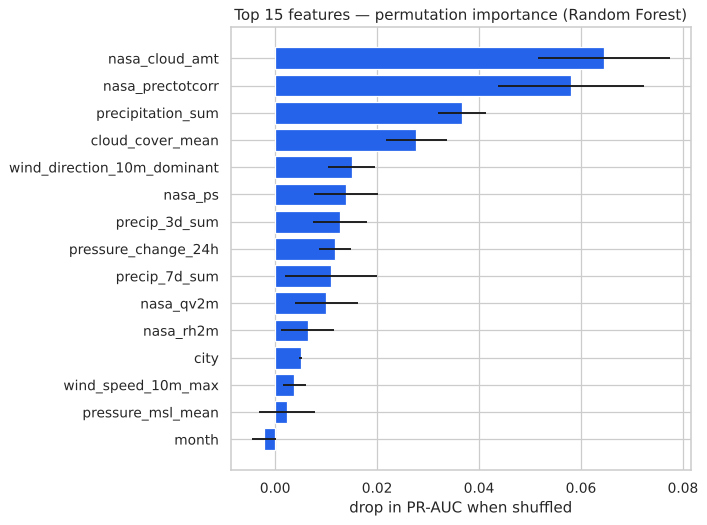

,feature,importance,std
0,nasa_cloud_amt,0.0645,0.0129
1,nasa_prectotcorr,0.0581,0.0143
2,precipitation_sum,0.0367,0.0047
3,cloud_cover_mean,0.0277,0.0060
4,wind_direction_10m_dominant,0.0150,0.0047
5,nasa_ps,0.0139,0.0063
6,precip_3d_sum,0.0127,0.0052
7,pressure_change_24h,0.0117,0.0032
8,precip_7d_sum,0.0110,0.0091
9,nasa_qv2m,0.0100,0.0062


In [24]:
# permutation feature importance
sub = X_val.sample(n=min(4000, len(X_val)), random_state=SEED)
pi = permutation_importance(final_model, sub, y_val.loc[sub.index], scoring="average_precision",
                            n_repeats=2 if QUICK_TEST else 5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": INPUT_COLUMNS, "importance": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importance", ascending=False).reset_index(drop=True)
top = imp.head(15)
plt.figure(figsize=(8, 6))
plt.barh(top["feature"][::-1], top["importance"][::-1], xerr=top["std"][::-1], color=RAIN_C)
plt.xlabel("drop in PR-AUC when shuffled")
plt.title(f"Top 15 features — permutation importance ({best_name})")
savefig("14_feature_importance")
imp.head(15).round(4)

In [25]:
# save the final pipeline and metadata with joblib
MODEL_FILE = MODELS / "rainfall_pipeline.joblib"
joblib.dump(final_model, MODEL_FILE, compress=3)

num_cols = [c for c in INPUT_COLUMNS if c not in CATEGORICAL]
HELPERS = ["rh_mean", "dew_point_mean", "temperature_2m_min"]
full_train = full[full["date"] <= TRAIN_END]
metadata = {
    "model_name": best_name,
    "best_params": {k: (v if isinstance(v, (int, str, type(None))) else float(v))
                    for k, v in best_search.best_params_.items()},
    "threshold": THRESHOLD,
    "target": info["target"],
    "input_columns": INPUT_COLUMNS,
    "cities": sorted(df["city"].unique().tolist()),
    "split": {k: split.loc[k, "period"] for k in split.index},
    "rows": {k: int(split.loc[k, "rows"]) for k in split.index},
    "validation_comparison": comparison.round(4).to_dict(orient="index"),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "test_persistence_baseline": {k: round(float(v), 4) for k, v in persist_metrics.items()},
    "feature_importance": imp.head(20).round(5).to_dict(orient="records"),
    "train_medians": full_train[num_cols + HELPERS].median().round(3).to_dict(),
    "train_p01": X_train[num_cols].quantile(0.01).round(3).to_dict(),
    "train_p99": X_train[num_cols].quantile(0.99).round(3).to_dict(),
    "monthly_medians": {f"{city}|{month}": row.dropna().round(3).to_dict() for (city, month), row in
                        full_train.groupby(["city", "month"])[[c for c in num_cols if c != "month"] + HELPERS]
                        .median().iterrows()},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "data_sources": info["sources"],
    "data_downloaded_on_utc": info["downloaded_on_utc"],
}
(MODELS / "model_metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

reloaded = joblib.load(MODEL_FILE)
assert np.allclose(reloaded.predict_proba(X_test.head(200))[:, 1], proba_test[:200])
print(f"Saved {MODEL_FILE.name} ({MODEL_FILE.stat().st_size / 1e6:.1f} MB) + model_metadata.json — reload check passed")

Saved rainfall_pipeline.joblib (0.9 MB) + model_metadata.json — reload check passed


## 10. Summary
Copy the printed tables and figures in `reports/figures/` into the report. Pin the exact versions printed below
in `requirements.txt` (they must match the deployed Streamlit app so `joblib.load` works).

In [27]:
# library versions and final results
print(json.dumps(metadata["versions"], indent=2))
print(f"\nBest model: {best_name} | threshold {THRESHOLD:.3f}")
print("Test:", {k: round(v, 3) for k, v in test_metrics.items()})

{
  "python": "3.13.18",
  "scikit-learn": "1.9.1",
  "pandas": "3.0.5",
  "numpy": "2.5.3",
  "joblib": "1.6.0"
}

Best model: Random Forest | threshold 0.573
Test: {'F1': 0.586, 'Precision': 0.571, 'Recall': 0.602, 'Accuracy': 0.857, 'ROC-AUC': 0.879, 'PR-AUC': 0.636}
